In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path

if Path.cwd().name == "notebooks":
    %cd ..

/Users/alyaev.roman/Desktop/PhD_Code/drums


In [2]:
%run src/drums/models/flow_matching.py

0: train=1.4959, test=1.4909
500: train=0.7081, test=0.6095
1000: train=0.5999, test=0.5518
1500: train=0.6467, test=0.5630
2000: train=0.5190, test=0.5256
2500: train=0.5734, test=0.5445
3000: train=0.4885, test=0.5011
3500: train=0.5311, test=0.4879
4000: train=0.5143, test=0.4826
4500: train=0.4162, test=0.4376
5000: train=0.4292, test=0.4382
5500: train=0.3925, test=0.4141
6000: train=0.3521, test=0.4058
6500: train=0.5590, test=0.4156
7000: train=0.3709, test=0.4025
7500: train=0.4537, test=0.4191
8000: train=0.3802, test=0.4058
8500: train=0.4398, test=0.4036
9000: train=0.5632, test=0.3993
9500: train=0.4943, test=0.4000


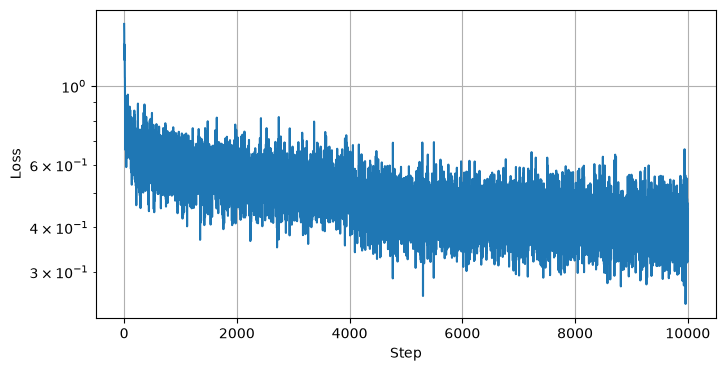

In [3]:
plt.figure(figsize=(8, 4))
plt.plot(history)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.show()

In [4]:
from itertools import permutations
import numpy as np
import jax
import jax.numpy as jnp
import jax.random as jr

orderings = jnp.array(list(permutations(range(3))))


def procrustes_error(target, prediction):
    target = target - target.mean(axis=0)

    def ordering_error(ordering):
        candidate = prediction[ordering]
        candidate = candidate - candidate.mean(axis=0)
        u, _, vt = jnp.linalg.svd(candidate.T @ target, full_matrices=False)
        aligned = candidate @ (u @ vt)
        return jnp.mean(
            jnp.linalg.norm(target - aligned, axis=1)
            / jnp.linalg.norm(target, axis=1)
        )

    return jnp.min(jax.vmap(ordering_error)(orderings))


batch_error = jax.jit(jax.vmap(procrustes_error))


def evaluate(model, spectra, vertices, n_draws=4, n_steps=100, seed=123):
    errors = []
    for draw_key in jr.split(jr.PRNGKey(seed), n_draws):
        keys = jr.split(draw_key, len(spectra))
        chunks = []
        for start in range(0, len(spectra), 128):
            stop = start + 128
            predictions = jax.vmap(
                lambda spectrum, key: sample(model, spectrum, key, n_steps=n_steps)
            )(spectra[start:stop], keys[start:stop])
            chunks.append(np.asarray(batch_error(vertices[start:stop], predictions)))
        errors.append(np.concatenate(chunks))
    return np.stack(errors)

In [5]:
assert spectra.shape == (1000, 30)
assert vertices.shape == (1000, 3, 2)
N_DRAWS, N_STEPS = 4, 100
errors17 = evaluate(model, spectra, vertices, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Seed 17:", "train", errors17[:, :900].mean(), "test", errors17[:, 900:].mean())

Seed 17: train 0.084136635 test 0.09254377


In [6]:
model18, history18, spectra18, vertices18 = main(seed=18)
errors18 = evaluate(model18, spectra18, vertices18, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Seed 18:", "train", errors18[:, :900].mean(), "test", errors18[:, 900:].mean())

0: train=1.5497, test=1.6419
500: train=0.7979, test=0.6330
1000: train=0.6521, test=0.5743
1500: train=0.5812, test=0.5643
2000: train=0.5470, test=0.5285
2500: train=0.5973, test=0.5340
3000: train=0.5189, test=0.5162
3500: train=0.4975, test=0.5005
4000: train=0.6433, test=0.4842
4500: train=0.5809, test=0.4790
5000: train=0.5237, test=0.4324
5500: train=0.3740, test=0.4175
6000: train=0.4971, test=0.4037
6500: train=0.4229, test=0.4158
7000: train=0.4944, test=0.4126
7500: train=0.4420, test=0.4132
8000: train=0.5369, test=0.4077
8500: train=0.5088, test=0.3950
9000: train=0.4664, test=0.4041
9500: train=0.3854, test=0.3996
Seed 18: train 0.08942759 test 0.096105434


In [7]:
# Baseline: log + standardise, AdamW, warmup + cosine, clipping, all orderings.
baseline = {17: (0.0054, 0.0058), 18: (0.0054, 0.0065)}
scores = []
print(f"All-orderings Procrustes error; FM averages {N_DRAWS} draws, {N_STEPS} Euler steps")
print("seed | FM train | FM test | baseline train | baseline test")
for seed, errors in [(17, errors17), (18, errors18)]:
    train_error, test_error = errors[:, :900].mean(), errors[:, 900:].mean()
    scores.append((train_error, test_error))
    b_train, b_test = baseline[seed]
    print(f"{seed:4d} | {train_error:.4f}   | {test_error:.4f}  | {b_train:.4f}         | {b_test:.4f}")
mean_train, mean_test = np.mean(scores, axis=0)
print(f"mean | {mean_train:.4f}   | {mean_test:.4f}  | 0.0054         | 0.0061")
print("Baseline means above are the rounded values reported in triangle_dataset_experiments.md.")
print("FM test std across sampling draws:",
      {seed: float(errors[:, 900:].mean(axis=1).std(ddof=1))
       for seed, errors in [(17, errors17), (18, errors18)]})

All-orderings Procrustes error; FM averages 4 draws, 100 Euler steps
seed | FM train | FM test | baseline train | baseline test
  17 | 0.0841   | 0.0925  | 0.0054         | 0.0058
  18 | 0.0894   | 0.0961  | 0.0054         | 0.0065
mean | 0.0868   | 0.0943  | 0.0054         | 0.0061
Baseline means above are the rounded values reported in triangle_dataset_experiments.md.
FM test std across sampling draws: {17: 0.006031827535480261, 18: 0.007025944534689188}


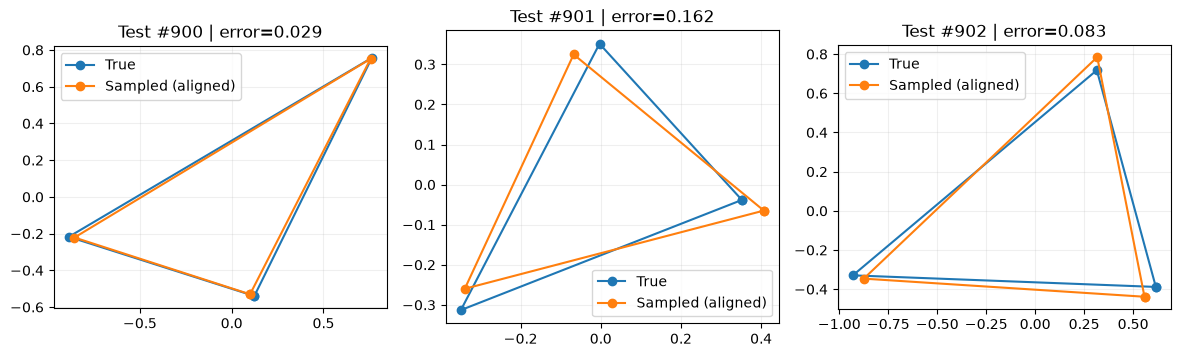

In [8]:
indices = [900, 901, 902]
keys = jr.split(jr.PRNGKey(456), len(indices))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, index, key in zip(axes, indices, keys):
    target = np.asarray(vertices[index])
    target = target - target.mean(axis=0)
    prediction = np.asarray(sample(model, spectra[index], key, n_steps=N_STEPS))

    candidates = prediction[np.asarray(orderings)]
    candidates = candidates - candidates.mean(axis=1, keepdims=True)
    u, _, vt = np.linalg.svd(candidates.transpose(0, 2, 1) @ target)
    aligned = candidates @ (u @ vt)
    errors = np.mean(
        np.linalg.norm(target - aligned, axis=2)
        / np.linalg.norm(target, axis=1), axis=1
    )
    best = np.argmin(errors)

    for triangle, label in [(target, "True"), (aligned[best], "Sampled (aligned)")]:
        closed = np.vstack([triangle, triangle[0]])
        ax.plot(closed[:, 0], closed[:, 1], "o-", label=label)
    ax.set_title(f"Test #{index} | error={errors[best]:.3f}")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()